# 08 - Summarizing and combining

Last time we got a file off the disk and into a table we could trust. This time we do the two things that turn a table into an answer:

- **Summarizing** - questions about *groups* of rows rather than single ones
- **Combining** - putting two tables together, and checking that it worked

The notebook covers both:

- Grouping and aggregating: `groupby`, `.agg()`, and one row per group
- The index of a grouped result: `set_index` and `reset_index`
- Transforming within groups: `.transform()`, `ffill`, `diff`, `pct_change` - one row per *original* row
- Working with dates: `to_datetime`, date formats, the `.dt` accessor
- Resampling a time series: `resample`, up and down
- Combining tables: `concat`, duplicates, `merge`, and validating a merge
- Per person or per country: two averages that answer different questions

As always, we start by importing what we need and loading our own data.

In [159]:
import numpy as np
import pandas as pd

Here is the function we finished with last time: it reads the file, drops the rows with no emissions figure, and adds emissions per person.

In [160]:
def load_emissions(path):
    """
    Read the emissions file and return it ready to use.

    Parameters
    ----------
    path : str
        Path to the emissions CSV file.

    Returns
    -------
    DataFrame
        One row per country per year, with rows missing total emissions
        dropped and emissions per person added as a column.
    """
    emissions = pd.read_csv(path)

    emissions = emissions.dropna(subset=["co2_total"])
    emissions["co2_pc"] = emissions["co2_total"] * 1_000_000 / emissions["population"]

    return emissions


co2 = load_emissions("../data/co2_emissions.csv")

print(co2.shape)
co2.head(3)

(5904, 12)


,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,co2_pc
0,Afghanistan,AFG,2000,1.0093,20130327,18.558,174.93,4.4,57.946,NaN,45.0,0.050138
1,Afghanistan,AFG,2001,0.9402,20284307,18.741,138.71,9.3,57.947,NaN,45.6,0.046351
2,Afghanistan,AFG,2002,0.9388,21378117,18.941,178.95,14.1,57.940,1.2761,37.8,0.043914


## Grouping and aggregating

Here is a question the table looks like it can answer. **How much CO₂ did the world emit each year?**

Every row is one entity in one year. So: take all the rows for a year, add up their emissions, and do that for each year. That is a loop over years, but pandas has a shorter way, called `groupby`.


In [161]:
co2.groupby("year")["co2_total"].sum().tail(3)

year
2021    312230.8520
2022    314199.0783
2023    320155.6020
Name: co2_total, dtype: float64

Three moves in one line: 
- **split** the rows into groups by their `year`
- **apply** `sum` to the `co2_total` column of each group
- **combine** the answers into one result

That is the whole idea, and it has a name - **split-apply-combine**. Every `groupby` you will ever write is those three steps; the only things that change are what you split on and what you apply.

> ⚠️ **Warning:** That answer is **wrong**. The table contains rows like `World` and `East Asia & Pacific`, which are groupings of countries, so summing every row counts the same emissions several times over. We come back to it later.

### The grouped object computes nothing

It is worth seeing what `groupby` actually returns, because it is not a table.

In [162]:
by_year = co2.groupby("year")

by_year

A `DataFrameGroupBy`. It knows which rows belong to which group and has computed nothing at all - it is waiting to be told what to apply. That is why the two halves are always written together: `.groupby("year")` on its own is a question with no verb.

Pick a column first and you get one answer per group.

In [163]:
co2.groupby("year")["co2_pc"].mean().tail(3)

year
2021    4.525511
2022    4.495202
2023    4.406028
Name: co2_pc, dtype: float64

### Counting: `.size()` and `.count()`

Two ways to count, and the difference matters.

- `.size()` counts **rows** in each group.
- `.count()` counts **non-missing values** in a column of each group.

In [164]:
counts = pd.DataFrame({
    "rows": co2.groupby("year").size(),
    "renew_energy": co2.groupby("year")["renew_energy"].count(),
})

counts.tail(5)

,rows,renew_energy
year,,
2019,246,246
2020,246,246
2021,246,203
2022,246,66
2023,246,0


Every year has the same 246 rows, and until 2020 every row has a renewable energy figure. Then 203, then 66, then **none at all**. That is the publication lag we found last time, seen from a different direction: the rows are all there, the values are not.

Use `.size()` when you want to know how big a group is, and `.count()` when you want to know how
much of it you can actually use.

### Several statistics at once: `.agg()`

`.mean()` gives you one statistic. Real summary tables want several. `.agg()` takes a **list of
function names, written as strings**, and gives you a column for each.

In [165]:
co2.groupby("year")["co2_pc"].agg(["mean", "median", "max"]).tail(3)

,mean,median,max
year,,,
2021,4.525511,2.609076,74.734297
2022,4.495202,2.643982,78.726280
2023,4.406028,2.686580,78.857111


These are the aggregation functions worth knowing. All of them collapse a group to a single value, and all of them can be written either as a method or as a string inside `.agg()`.

| | |
|---|---|
| `"sum"` | total |
| `"mean"`, `"median"` | average, middle value |
| `"min"`, `"max"` | smallest, largest |
| `"std"`, `"var"` | standard deviation, variance |
| `"count"` | non-missing values |
| `"size"` | rows, missing or not |
| `"first"`, `"last"` | first and last value in the group |
| `"nunique"` | how many distinct values |

The list form works when every statistic is applied on the **same column**. Often you want different statistics of different columns, and then there is a second form: name each output column, and say what it is made of.

```python
grouped.agg(
    output_name = ("input_column", "function"),
    ...
)
```

In [166]:
summary = co2.groupby("year").agg(
    entities=("co2_total", "count"),
    total_co2=("co2_total", "sum"),
    mean_pc=("co2_pc", "mean"),
).round(0)

summary.tail(3)

,entities,total_co2,mean_pc
year,,,
2021,246,312231.0,5.0
2022,246,314199.0,4.0
2023,246,320156.0,4.0


One line per output column, each saying exactly where it came from. This is the form to reach for when you are building a table somebody else will read, because the column names are yours rather than pandas' guesses.

> 💡 **Tip:** `.round(2)` on the result rounds every number in it, which usually makes a
summary table far easier to read. Round for **display**, at the end - not in the middle of a
calculation, where you would be throwing away precision you still need.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>co2 = pd.read_csv("../data/co2_emissions.csv")</code></pre>

<p>Build one summary table with a row per year and three named columns: the number of entities that
have a <code>gdp_pc</code> figure, the average <code>gdp_pc</code>, and the highest
<code>urban</code> share. Display the last five years, rounded to one decimal.</p>
</div>

In [167]:
co2 = pd.read_csv("../data/co2_emissions.csv")

co2.groupby("year").agg(
    gdp_entities=("gdp_pc", "count"), # amount of entities that have a gdp_pc
    avg_gdp_pc=("gdp_pc", "mean"), # average gdp_pc
    highest_urban=("urban", "max") # the highest urban share
).tail(5).round(1)

,gdp_entities,avg_gdp_pc,highest_urban
year,,,
2019,254,17689.2,100.0
2020,253,16422.9,100.0
2021,253,18973.0,100.0
2022,252,19671.2,100.0
2023,247,20658.7,100.0


## The index of a grouped result

Look closely at what came back from those last few cells. The years are not in a column. They are down the left-hand side, where the row numbers usually go.

That is because they **are** the index now. `groupby` puts whatever you grouped on into the index of the result, which makes sense: the group label is what identifies the row.

In [168]:
totals = co2.groupby("year")["co2_total"].sum()

print(type(totals))
print(totals.index)

<class 'pandas.Series'>
Index([2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023],
      dtype='int64', name='year')


A `Series`, indexed by year. That is often exactly what you want. Index alignment means you can divide one grouped result by another and the years line themselves up, and plotting a Series puts the index along the horizontal axis without being asked.

But it is a nuisance the moment you want to treat the result as an ordinary table - filter it, join it, or write it to a file - because **`year` is not a column**, and asking for it as one fails.

In [169]:
# KeyError
totals["year"]

KeyError: 'year'

### `reset_index` moves the index back into a column

In [ ]:
totals_df = totals.reset_index()

print(type(totals_df))
totals_df.tail(3)

<class 'pandas.DataFrame'>


,year,co2_total
21,2021,312230.8520
22,2022,314199.0783
23,2023,320155.6020


Now it is a DataFrame with two ordinary columns, and everything from last time works on it again. `reset_index()` is the most common thing to write after a `groupby`, and when a grouped result is fighting you, it is usually the answer.

> 📝 **Note:** `reset_index()` takes a `drop` parameter. `reset_index(drop=True)` throws the
old index away instead of turning it into a column, which is what you want when the index is
meaningless row numbers rather than something you care about.

### `set_index` goes the other way

`set_index` takes a column and makes it the index.

In [ ]:
totals_by_year = totals_df.set_index("year")

totals_by_year.tail(3)

,co2_total
year,
2021,312230.8520
2022,314199.0783
2023,320155.6020


In [ ]:
totals_by_year.loc[2023, "co2_total"]

np.float64(320155.602)

Which raises the obvious question: why would you ever do that on purpose?

Because an index is not decoration - it is what pandas **aligns on**, as we saw when two Series with different labels were added together. A table indexed by something meaningful can be looked up by label with `.loc`, as above; it lines up automatically with any other table indexed the same way.

## Transforming within groups

Everything so far **collapsed** the table: 5 904 rows in, 24 rows out, one per group.

Often that is not what you want. You want the group's answer put back **beside every row it came
from**, so that a row can be compared against its own group. Norway's emissions per person in 2020 are only interesting next to Norway's usual level.

The methods in this section all do that. They take a group and give back **one value per original row**, so their results can be assigned straight into a column.

In [ ]:
co2.groupby("country")["co2_pc"].agg("mean").shape

(246,)

In [ ]:
co2.groupby("country")["co2_pc"].transform("mean").shape # transforming: calculating the mean of each country of the co2_pc, and returned it for each country (?)

(5904,)

246 against 5 904. `.mean()` gave one number per country; `.transform("mean")` gave every row its own country's number, repeated as many times as that country has rows. **Same answer, different shape.**

### The methods

`.transform()` takes any of the aggregation names from earlier and broadcasts the result back. The rest are methods that compare a row against its **neighbors** rather than against a summary.

| | |
|---|---|
| `.transform("mean")` | the group's statistic, repeated on every row of the group |
| `.diff()` | this row minus the previous row |
| `.pct_change()` | the same, as a fraction of the previous row |
| `.shift(1)` | the previous row's value, moved down one |
| `.cumsum()` | running total down the group |
| `.ffill()` | fill a hole with the last known value **before** it |
| `.bfill()` | fill a hole with the next known value **after** it |

Because several of these look at the row before or after, the rows have to be **in order**. Our panel is one series per country stacked on top of the next, so we sort by country and year first.

In [ ]:
panel = co2.sort_values(["country", "year"]).copy()

panel["country_mean_pc"] = panel.groupby("country")["co2_pc"].transform("mean")
panel["previous"] = panel.groupby("country")["co2_total"].shift(1)
panel["change"] = panel.groupby("country")["co2_total"].diff()
panel["pct_change"] = panel.groupby("country")["co2_total"].pct_change() * 100

panel[panel["country"] == "Norway"][
    ["year", "co2_total", "previous", "change", "pct_change", "country_mean_pc"]
].tail(4).round(2)

,year,co2_total,previous,change,pct_change,country_mean_pc
4292,2020,43.71,45.35,-1.64,-3.61,9.09
4293,2021,44.43,43.71,0.72,1.65,9.09
4294,2022,43.55,44.43,-0.88,-1.98,9.09
4295,2023,41.60,43.55,-1.94,-4.46,9.09


Four different questions about Norway, in one table:
- `country_mean_pc` is Norway's own 24-year average per person (repeated on every Norwegian row)
- `previous` is last year's figure moved down a row
- `change` is the difference
- `pct_change` is that difference as a percentage

The first of these is the pattern worth remembering: **compute a baseline per group, then measure every row against it.** Temperature anomalies, deviations from trend, shares of a total and index numbers are all these same two lines.

In [ ]:
year_2020 = panel[panel["year"] == 2020]

print("entities with a 2020 figure:", len(year_2020))
print("emissions fell in 2020:     ", (year_2020["change"] < 0).sum())

entities with a 2020 figure: 246
emissions fell in 2020:      187


187 of 246 entities emitted less in 2020 than in 2019 - the pandemic, visible in one grouped `.diff()`.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>co2 = pd.read_csv("../data/co2_emissions.csv")</code></pre>

<p>Add a column giving how far each row's <code>urban</code> share is from its own country's average
<code>urban</code> share, and display Norway's last five years, rounded to two decimals.</p>
</div>

In [ ]:
co2 = pd.read_csv("../data/co2_emissions.csv")

co2["country_urban_mean"] = co2.groupby("country")["urban"].transform("mean") # country mean

co2["urban_vs_mean"] = co2["urban"] - co2["country_urban_mean"] # difference

co2.head()

,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,country_urban_mean,urban_vs_mean
0,Afghanistan,AFG,2000,1.0093,20130327,18.558,174.93,4.4,57.946,NaN,45.0,22.500917,-3.942917
1,Afghanistan,AFG,2001,0.9402,20284307,18.741,138.71,9.3,57.947,NaN,45.6,22.500917,-3.759917
2,Afghanistan,AFG,2002,0.9388,21378117,18.941,178.95,14.1,57.940,1.2761,37.8,22.500917,-3.559917
3,Afghanistan,AFG,2003,1.0172,22733049,19.160,198.87,19.0,58.084,0.7313,36.7,22.500917,-3.340917
4,Afghanistan,AFG,2004,0.9024,23560654,19.399,221.76,23.8,58.151,0.4589,44.2,22.500917,-3.101917


### Filling gaps

`ffill` and `bfill` belong to the same family and are worth their own demonstration, because they are a **decision** and not a repair. We know `renew_energy` stops being published in the most recent years. A forward fill carries each country's last observed share forward into them.

In [ ]:
panel["renew_filled"] = panel.groupby("country")["renew_energy"].ffill() # replaces all missing with the last known value. If 2004 is mising for AFG, then use 2003 if we have that.

print("missing before:", panel["renew_energy"].isna().sum())
print("missing after: ", panel["renew_filled"].isna().sum())

panel[panel["country"] == "Norway"][["year", "renew_energy", "renew_filled"]].tail(4)

missing before: 471
missing after:  2


,year,renew_energy,renew_filled
4292,2020,60.9,60.9
4293,2021,61.4,61.4
4294,2022,NaN,61.4
4295,2023,NaN,61.4


471 holes down to 2, and Norway's 2021 figure of 61.4 copied into 2022 and 2023.

**And now the part you have to decide rather than run.** A forward fill asserts that the value did not change. Over one year, for a share that moves slowly, that is defensible. Over three years, for exactly the years everyone wants to look at, it invents a flat line that never happened - and nothing downstream will ever tell you the number was made up. Filling is a claim about the world, not a tidying step.

`bfill` is the same method pointing the other way, and it earns its keep when a label is recorded only once. If a file gives each country's region in its final year only, one `bfill` within country carries it back over every earlier year.

### The group is not optional

Every method in this section was written with a `groupby` in front of it. Here is what happens
without one.

In [ ]:
small = pd.DataFrame({
    "country": ["Norway", "Norway", "Norway", "Sweden", "Sweden", "Sweden"],
    "year": [2021, 2022, 2023, 2021, 2022, 2023],
    "renew_energy": [60.1, 61.4, np.nan, np.nan, 50.2, 51.0],
    "co2_total": [40, 38, 37, 35, 34, 33],
})

small["ffill_grouped"] = small.groupby("country")["renew_energy"].ffill()
small["ffill_ungrouped"] = small["renew_energy"].ffill()

small[["country", "year", "renew_energy", "ffill_grouped", "ffill_ungrouped"]]

,country,year,renew_energy,ffill_grouped,ffill_ungrouped
0,Norway,2021,60.1,60.1,60.1
1,Norway,2022,61.4,61.4,61.4
2,Norway,2023,NaN,61.4,61.4
3,Sweden,2021,NaN,NaN,61.4
4,Sweden,2022,50.2,50.2,50.2
5,Sweden,2023,51.0,51.0,51.0


Norway's 2023 hole is filled with 61.4 either way. Sweden's 2021 hole is where the two disagree. Grouped, it stays `NaN`: Sweden has no earlier value to carry forward. Ungrouped, it gets 61.4 - **Norway's** figure, carried straight on into the next country because nothing told `ffill` where Norway ends. The ungrouped fill leaves fewer missing values, which looks better and is much worse.

> ⚠️ **Warning:** Every method in this section looks at the row before or the row after, and none of them knows where one country ends and the next begins. **Group first** - and the group is whatever the rows are a series *within*.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>co2 = pd.read_csv("../data/co2_emissions.csv")
co2 = co2.sort_values(["country", "year"])</code></pre>

<p>Add a column giving each country's year-on-year <b>percentage</b> change in
<code>co2_total</code>, and display the five largest single-year rises in the whole table.</p>
</div>

In [ ]:
co2 = pd.read_csv("../data/co2_emissions.csv")
co2 = co2.sort_values(["country", "year"])

co2["co2_change"] = co2.groupby("country")["co2_total"].pct_change()*100

# displaying the 5 highest
# co2.sort_values("co2_change", ascending=False).head() # method 1

co2.nlargest(5, "co2_change") # method 2

,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,co2_change
2188,Greenland,GRL,2004,0.6039,56898,82.563,32031.00,100.0,0.587,0.2249,6.7,43035.714286
5826,Turks and Caicos Islands,TCA,2018,0.1897,41559,92.680,31625.62,100.0,1.053,0.0028,0.4,114.835787
2969,"Korea, Dem. People's Rep.",PRK,2017,73.5427,25817709,61.821,NaN,44.2,21.568,NaN,10.2,104.131612
3087,Lao PDR,LAO,2015,8.9275,6801645,33.124,2121.01,89.7,10.455,5.5248,53.3,103.485059
5644,Timor-Leste,TLS,2004,0.5158,929074,25.704,474.42,30.4,22.421,NaN,44.0,95.452823


## Working with dates

A great deal of real data is a **time series**: the same thing measured over and over, with a date attached. Before you can group, filter or plot by time, pandas has to know that the date column is a date and not a piece of text.

New dataset: the daily closing level of the **NASDAQ Composite** stock index, from 1971 to 2025.

In [ ]:
nasdaq = pd.read_csv("../data/NASDAQ.csv")

print(nasdaq.shape)
print(nasdaq.dtypes)
nasdaq.head(3)

(13842, 2)
Date          str
NASDAQ    float64
dtype: object


,Date,NASDAQ
0,1971-02-05,100.0
1,1971-02-08,100.8
2,1971-02-09,100.8


13 842 trading days and two columns. And `Date` is **`str`** - as far as pandas is concerned,
`"1971-02-05"` is a piece of text like `"Bergen"`.

### `pd.to_datetime`, and always say the format

`pd.to_datetime` converts text into real dates. It can guess the format, but you should not let it.

In [ ]:
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")

print(nasdaq["Date"].dtype)
print(nasdaq["Date"].min(), "to", nasdaq["Date"].max())

datetime64[us]
1971-02-05 00:00:00 to 2025-12-30 00:00:00


`datetime64` - a point in time, which pandas can sort, compare and do arithmetic on.

The `format` string describes how the date is *written*, using a code for each piece:

| Code | Means | Example |
|---|---|---|
| `%Y` | four-digit year | `2024` |
| `%y` | two-digit year | `24` |
| `%m` | month as a number | `03` |
| `%b` | short month name | `Mar` |
| `%B` | full month name | `March` |
| `%d` | day of the month | `09` |
| `%H` | hour, 24-hour clock | `14` |
| `%M` | minute | `30` |
| `%S` | second | `05` |

Everything else in the string is taken literally, so `"%d/%m/%Y"` matches `09/03/2024`,
`"%d.%m.%Y"` matches `09.03.2024`, and `"%B %d, %Y"` matches `March 09, 2024`.

### Why the format is not optional

In [ ]:
visits = pd.DataFrame({
    "date": ["02/01/2021", "06/05/2021", "11/03/2021"],
    "patients": [14, 9, 22],
})

print("guessed:  ", list(pd.to_datetime(visits["date"]).dt.date))
print("told:     ", list(pd.to_datetime(visits["date"], format="%d/%m/%Y").dt.date))

guessed:   [datetime.date(2021, 2, 1), datetime.date(2021, 6, 5), datetime.date(2021, 11, 3)]
told:      [datetime.date(2021, 1, 2), datetime.date(2021, 5, 6), datetime.date(2021, 3, 11)]


Those are European dates - 2 January, 6 May, 11 March. Left to guess, pandas reads them the American
way round and returns **1 February, 5 June and 3 November** instead.

No error, and no warning. Every day number here is 12 or below, so both readings are valid calendar
dates and there is nothing for pandas to complain about. The dates are simply wrong, and every
grouping, filter and plot built on them afterwards is wrong too.

### `.dt` gets the pieces out

A real date knows what year, month and day it is made of. The **`.dt` accessor** is how you ask for one piece at a time: `.dt.year`, `.dt.month`, `.dt.day`, `.dt.quarter`, `.dt.date`, and
`.dt.day_name()` for the weekday as text.

In [ ]:
nasdaq["year"] = nasdaq["Date"].dt.year
nasdaq["month"] = nasdaq["Date"].dt.month
nasdaq["weekday"] = nasdaq["Date"].dt.day_name()

nasdaq.head(3)

,Date,NASDAQ,year,month,weekday
0,1971-02-05,100.0,1971,2,Friday
1,1971-02-08,100.8,1971,2,Monday
2,1971-02-09,100.8,1971,2,Tuesday


### Filtering by date

Real dates compare properly, so filtering to a period is a boolean mask like any other. The
boundaries can be written as strings and pandas will read them as dates.

In [ ]:
crash = nasdaq[(nasdaq["Date"] >= "2020-02-01") & (nasdaq["Date"] <= "2020-04-30")]

print(len(crash), "trading days")
print("high:", crash["NASDAQ"].max().round(1), " low:", crash["NASDAQ"].min().round(1))

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")</code></pre>

<p>Using the <code>.dt</code> accessor and a <code>groupby</code>, report the average closing level in
each <b>decade</b>. Display the result.</p>

<p><i>Hint: integer division by 10 and back, <code>year // 10 * 10</code>, turns 1987 into
1980.</i></p>
</div>

In [ ]:
nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")

nasdaq["decade"] = nasdaq["Date"].dt.year // 10 * 10
nasdaq.groupby("decade")["NASDAQ"].mean()

decade
1970      104.624066
1980      296.667286
1990     1104.079272
2000     2194.094791
2010     4744.158386
2020    14574.572196
Name: NASDAQ, dtype: float64

In [ ]:
nasdaq

,Date,NASDAQ,decade
0,1971-02-05,100.0,1970
1,1971-02-08,100.8,1970
2,1971-02-09,100.8,1970
3,1971-02-10,100.7,1970
4,1971-02-11,101.4,1970
...,...,...,...
13837,2025-12-23,23561.8,2020
13838,2025-12-24,23613.3,2020
13839,2025-12-26,23593.1,2020
13840,2025-12-29,23474.3,2020


## Resampling a time series

Daily data is rarely the resolution you want to report at. `resample` changes the frequency of a time series: **downsampling** to a coarser one (daily to monthly), or **upsampling** to a finer one (monthly to daily).

It needs the dates to be the **index**, which is what `set_index` was for, and it wants them in order, which is what `sort_index` is for.

In [ ]:
prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]

prices.head(3)

Date
1971-02-05    100.0
1971-02-08    100.8
1971-02-09    100.8
Name: NASDAQ, dtype: float64

### Downsampling

`resample` takes a string saying which period to group into, and then a verb saying what to do with
each period - exactly like `groupby`.

| Code | Period |
|---|---|
| `"D"` | day |
| `"W"` | week |
| `"ME"` | month end |
| `"QE"` | quarter end |
| `"YE"` | year end |

The aggregation function `.last()` returns the closing level of the period.

In [ ]:
print("daily rows:  ", len(prices))
print("weekly rows: ", len(prices.resample("W").last()))
print("monthly rows:", len(prices.resample("ME").last())) # month end
print("yearly rows: ", len(prices.resample("YE").last())) # year end

daily rows:   13842
weekly rows:  2866
monthly rows: 659
yearly rows:  55


13 842 daily observations become 55 annual ones.

In [ ]:
annual = prices.resample("YE").last()

annual.head(3).round(1)

Date
1971-12-31    114.1
1972-12-31    133.7
1973-12-31     92.2
Freq: YE-DEC, Name: NASDAQ, dtype: float64

The verb matters and is yours to choose: `.last()` for a closing level, `.mean()` for an average level, `.max()` for the peak, `.sum()` for a quantity like traded volume or rainfall. Summing a *price* would be meaningless, but pandas will do it happily if you ask.

Because the result is an ordinary Series indexed by date, the transformation methods from earlier work on it directly.

In [ ]:
annual_return = annual.pct_change() * 100

print("worst years:")
print(annual_return.sort_values().head(3).round(1))
print()
print("best years:")
print(annual_return.sort_values(ascending=False).head(3).round(1))

worst years:
Date
2008-12-31   -40.5
2000-12-31   -39.3
1974-12-31   -35.1
Name: NASDAQ, dtype: float64

best years:
Date
1999-12-31    85.6
1991-12-31    56.8
2003-12-31    50.0
Name: NASDAQ, dtype: float64


2008 and 2000, the financial crisis and the dot-com crash. And 1999, the year before the
dot-com crash, up 86%.

### Upsampling

Going the other way asks for rows that do not exist in the data, and this is where `resample` shows what it really is. Ask for **every calendar day**.

In [ ]:
daily = prices.resample("D").last()

print("trading days in the file:", len(prices))
print("calendar days produced: ", len(daily))
print("of which empty:         ", daily.isna().sum())
print()
print(daily.loc["2020-03-05":"2020-03-10"].round(1))

trading days in the file: 13842
calendar days produced:  20053
of which empty:          6211

Date
2020-03-05    8738.6
2020-03-06    8575.6
2020-03-07       NaN
2020-03-08       NaN
2020-03-09    7950.7
2020-03-10    8344.2
Freq: D, Name: NASDAQ, dtype: float64


20 053 calendar days from 13 842 trading days, and **6 211 of them empty**. Saturday 7 March and
Sunday 8 March 2020 are `NaN` because no trading happened - and those rows now exist, which they did not before.

That is the point of `resample`:

> **`resample` builds its periods out of the calendar, not out of the rows you happen to have.**

A gap in the data becomes a visible `NaN` rather than silently disappearing. If you want the gaps filled, that is a separate decision and you make it yourself.

In [ ]:
print("empty after ffill:", prices.resample("D").ffill().isna().sum()) #replaces nan with the last known value (value from the friday before)

empty after ffill: 0


### `resample` or `groupby`?

You could imagine doing the monthly figures with `groupby` on `.dt.month` instead. Try it.

In [ ]:
len(prices.groupby(prices.index.month).mean())

12

In [ ]:
len(prices.resample("ME").mean()) # more rows because it also groups by year

659

In [ ]:
# We can do this with groupby as well, like this:
len(prices.groupby([prices.index.month, prices.index.year]).mean())

659

Twelve rows against 659. `.dt.month` returns the number 1 for **every January in the dataset**, so those groups mix January 1971 with January 2025 - a 55-year span over which the index went from 100 to 23 419. The average of that is not a fact about anything.

The twelve rows come from the key, not from `groupby`: `.dt.month` gives every January the number 1, whichever year it is in. Group on the year and the month together and `groupby` gives 659 rows too, with the same numbers as `resample`. So for many questions both work. The choice comes down to whether you are **grouping by labels** or **changing the frequency of a time series**.

Use `groupby` to split rows by values, including date parts like "every January" or "every Monday". Use `resample` when you want a time series at a different frequency, such as daily to weekly or monthly to daily, with every period in the calendar present.

| | `groupby` | `resample` |
|---|---|---|
| **Purpose** | Splitting rows by distinct values or categories | Changing the frequency of a time series, coarser (downsampling) or finer (upsampling) |
| **Works on** | Any column: strings, numbers, dates | A series with dates as its index |
| **Periods with no rows** | Left out. A group with no data does not appear in the result | Kept. The row is created from the calendar, and shows as `NaN` for `.mean()` or `.last()`, and `0` for `.sum()` or `.count()` |
| **Dates** | Treated as labels: the year 2001 or month 1 is just a value to group on | Treated as time: it knows weeks, month ends, quarters and multiples of them, like `"2W"` |


<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")
prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]</code></pre>

<p>Resample the series to <b>quarter</b> ends, taking the closing level of each quarter, and report
how many quarters the index ended lower than the quarter before.</p>
</div>

In [ ]:
nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")
prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]

quarterly = prices.resample("QE").last()

(quarterly.diff() < 0).sum()

np.int64(72)

## Combining tables

Everything so far has been one file at a time. Real work is rarely one file: a year per file, a
country per file, one file from each of ten colleagues - or, as here, the measurements in one file and the labels that explain them in another.

There are two ways to put tables together, and which you want depends on what the second table adds:

- **`concat`** adds **rows**: same columns, more observations.
- **`merge`** adds **columns**: same observations, more variables.

### `concat`: stacking

`pd.concat` takes a **list** of DataFrames and returns one.

In [ ]:
north = pd.DataFrame({
    "country": ["Norway", "Sweden", "Denmark"],
    "co2_pc": [7.5, 3.4, 4.6],
})

south = pd.DataFrame({
    "country": ["Spain", "Italy"],
    "co2_pc": [5.0, 5.4],
})

stacked = pd.concat([north, south])

stacked

,country,co2_pc
0,Norway,7.5
1,Sweden,3.4
2,Denmark,4.6
0,Spain,5.0
1,Italy,5.4


Five rows, as expected. But look down the left-hand side: **0, 1, 2, 0, 1**. `concat` stacked the indexes too, so two different rows are both labeled 0 - and the index is what pandas aligns on, so a duplicated index quietly breaks `.loc` and everything built on it.

In [ ]:
stacked.loc[0]

,country,co2_pc
0,Norway,7.5
0,Spain,5.0


Two rows returned for one label. The fix is `reset_index` with the `drop` parameter - these row numbers mean nothing, so throw them away rather than keeping them as a column.

In [ ]:
stacked = pd.concat([north, south]).reset_index(drop=True)

stacked

,country,co2_pc
0,Norway,7.5
1,Sweden,3.4
2,Denmark,4.6
3,Spain,5.0
4,Italy,5.4


If the tables do not have quite the same columns, `concat` keeps all of them and fills the gaps with `NaN` rather than refusing. That is convenient, and worth checking rather than trusting: a column of `NaN` you did not expect usually means two files disagree about a column name - `co2_pc` in one and `CO2_pc` in the other - and `concat` will not tell you.

> 📝 **Note:** `pd.concat([a, b], axis=1)` glues tables side by side instead, matching on the
index. It is occasionally right and usually not: when you want columns from another table, what you almost always want is a merge.

### Duplicates

Stacking files together is the commonest way to end up with the same row twice - a file listed twice in a folder, a cell run twice, two colleagues who both sent you January.

`.duplicated()` gives one `True` or `False` per row, marking rows identical to one seen earlier. It is a boolean mask, so summing it counts them, and `.drop_duplicates()` removes them.

In [ ]:
readings = pd.DataFrame({
    "station": ["Oslo", "Bergen", "Oslo", "Tromsø", "Bergen"],
    "year": [2023, 2023, 2023, 2023, 2023],
    "temp": [6.9, 8.4, 6.9, 3.1, 8.4],
})

print("duplicate rows:", readings.duplicated().sum())
readings.drop_duplicates()

duplicate rows: 2


,station,year,temp
0,Oslo,2023,6.9
1,Bergen,2023,8.4
3,Tromsø,2023,3.1


Rows 2 and 4 repeated rows 0 and 1 exactly, and dropping them lost nothing, because the duplicates **agreed**.

Here is the case that matters.

In [ ]:
readings_2 = pd.DataFrame({
    "station": ["Oslo", "Bergen", "Oslo", "Tromsø"],
    "year": [2023, 2023, 2023, 2023],
    "temp": [6.9, 8.4, 7.4, 3.1],
})

print("duplicate rows:", readings_2.duplicated().sum())
readings_2

duplicate rows: 0


,station,year,temp
0,Oslo,2023,6.9
1,Bergen,2023,8.4
2,Oslo,2023,7.4
3,Tromsø,2023,3.1


**Zero duplicates**, and Oslo is still in there twice - with two different temperatures. No row is a copy of another, so `.duplicated()` is right to say nothing.

To ask "is any station listed twice?", say which columns identify a row, using `subset`.

In [ ]:
print("repeated station-year keys:", readings_2.duplicated(subset=["station", "year"]).sum())

readings_2.drop_duplicates(subset=["station", "year"])

repeated station-year keys: 1


,station,year,temp
0,Oslo,2023,6.9
1,Bergen,2023,8.4
3,Tromsø,2023,3.1


> ⚠️ **Warning:** An exactly duplicated row is a mistake, and dropping it loses nothing. A repeated **key** with conflicting values is a question about your data - which figure is right, and why are there two? `drop_duplicates(subset=["station", "year"])` silently keeps 6.9 and discards 7.4 for no better reason than that it came first. Find out before you drop.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>info = pd.read_csv("../data/country_info.csv")</code></pre>

<p>This lookup table should have exactly one row per country. Check both things that could be wrong
with it: how many rows are exact duplicates, and how many <code>code</code> values appear more than
once. Print both counts.</p>
</div>

In [ ]:
info = pd.read_csv("../data/country_info.csv")

info.duplicated().sum()

np.int64(0)

In [ ]:
info.duplicated(subset=["code"]).sum()

np.int64(0)

### `merge`: columns from another table

`merge` matches rows in one table against rows in another on a shared value called a **key**.

Here is the second file - the one that will finally let us fix the total in CO2 emissions.

In [ ]:
info = pd.read_csv("../data/country_info.csv")

print(info.shape)
info.head(3)

(295, 4)


,name,code,region,incomeLevel
0,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income
1,Africa,AFR,Aggregates,Aggregates
2,Africa Eastern and Southern,AFE,Aggregates,Aggregates


In [ ]:
info["region"].value_counts()

region
Aggregates                                           78
Europe & Central Asia                                58
Sub-Saharan Africa                                   48
Latin America & Caribbean                            42
East Asia & Pacific                                  37
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         3
Name: count, dtype: int64

295 rows, one per entity: a `name`, a three-letter `code`, a `region` and an `incomeLevel`. And there is the column we need - the World Bank marks its own groupings with the region `"Aggregates"`.

### First, tidy the column names with `rename`

`incomeLevel` is camelCase, and everything in this course is snake_case. `rename` takes a dictionary of old name to new name and returns a new table.

In [ ]:
info = info.rename(columns={"incomeLevel": "income_level"})

info.columns

Index(['name', 'code', 'region', 'income_level'], dtype='str')

`rename` is worth knowing well beyond tidiness. It is how you make two tables agree about what a
column is called, which matters here because our two tables name the same thing differently: the
emissions file calls it `country`, the lookup file calls it `name`.

That gives two ways to merge on it - rename one side so the names match, or tell `merge` about both names with `left_on` and `right_on`:

```python
info.rename(columns={"name": "country"})     # then merge on="country"
co2.merge(info, left_on="country", right_on="name")   # or say both
```

Use `rename` when the mismatch is a nuisance you want gone for good, and `left_on`/`right_on` when it is a one-off. We will use both below.

### Look at the keys before you use them

A merge matches keys **exactly**. Not roughly, not case-insensitively: exactly. And text keys arrive dirty far more often than anybody expects, so it is worth two minutes looking first.

Every string method from the first half of this course - `.strip()`, `.lower()`, `.replace()`,
`.startswith()` - is available on a whole column at once through the **`.str` accessor**. It is
vectorized, exactly like the arithmetic on columns we did last time: no loop, one expression.

In [ ]:
print(info["name"].str.lower().head(3))
print()
print("names with whitespace to strip:", (info["name"] != info["name"].str.strip()).sum())

0                    afghanistan
1                         africa
2    africa eastern and southern
Name: name, dtype: str

names with whitespace to strip: 4


**Four of the 295 names have leading or trailing whitespace**, exactly as the World Bank publishes them. `"Sub-Saharan Africa "` and `"Sub-Saharan Africa"` look identical on screen and are two different strings.

`code` does not have the problem. Both facts matter, and we use both below.

### Merging

`.merge()` is called on one table and given the other, plus `on=` naming the shared column.

In [ ]:
panel = co2.merge(info[["code", "region", "income_level"]], on="code", how="left")

print("before:", co2.shape)
print("after: ", panel.shape)
panel[["country", "year", "co2_total", "region", "income_level"]].head(3)

before: (6240, 12)
after:  (6240, 14)


,country,year,co2_total,region,income_level
0,Afghanistan,2000,1.0093,"Middle East, North Africa, Afghanistan & Pakistan",Low income
1,Afghanistan,2001,0.9402,"Middle East, North Africa, Afghanistan & Pakistan",Low income
2,Afghanistan,2002,0.9388,"Middle East, North Africa, Afghanistan & Pakistan",Low income


Same number of rows, two extra columns. `how="left"` says *keep every row of the left-hand table, whether or not it found a match*, and it is the right choice here: we are decorating the emissions data, not filtering it.

The four kinds of join differ only in which unmatched rows survive:

| `how=` | Keeps |
|---|---|
| `"inner"` | only rows that matched on **both** sides - the default, and it deletes silently |
| `"left"` | every row of the left table; unmatched right-hand columns become `NaN` |
| `"right"` | every row of the right table |
| `"outer"` | everything from both sides |

Prefer `"left"` when one table is your data and the other is a lookup. Prefer `"inner"` only when you genuinely want the intersection - and even then, count what it cost you.

### A merge can make your table bigger

If a key appears **more than once** in the right-hand table, every match produces a row.

In [ ]:
countries = pd.DataFrame({
    "code": ["NOR", "SWE"],
    "name": ["Norway", "Sweden"],
})

visits = pd.DataFrame({
    "code": ["NOR", "NOR", "NOR", "SWE"],
    "year": [2021, 2022, 2023, 2023],
})

countries.merge(visits, on="code", how="left")

,code,name,year
0,NOR,Norway,2021
1,NOR,Norway,2022
2,NOR,Norway,2023
3,SWE,Sweden,2023


Two rows in, four rows out, from a **left** join. Nothing is wrong: Norway genuinely has three
matching rows. But if you expected one row per country and got this, every average you compute
afterwards is now weighted by how many times each country happened to appear.

**A merge can lose rows and a merge can gain rows, and neither one raises anything.** So you check.

### Validating a merge

Three checks, in increasing order of how much work they save you.

**1. Count the rows.** The cheapest thing in pandas, and the one that catches most of it. Below we deliberately merge on the dirty key to see what it costs - and because the key is called `country` in one table and `name` in the other, we name each side with `left_on` and `right_on`.

In [ ]:
merged_on_name = co2.merge(
    info[["name", "region"]],
    left_on="country",
    right_on="name",
    how="inner",
)

print("rows before:", len(co2))
print("rows after: ", len(merged_on_name))
print("lost:       ", len(co2) - len(merged_on_name))

rows before: 6240
rows after:  6192
lost:        48


**48 rows gone**, deleted by the inner join without comment. 48 out of 5 904 is under one percent - far too small to notice in a `.head()`, more than enough to be wrong about.

**2. `indicator=True` says which side each row came from.** Counting tells you *that* something went missing; this tells you *what*. Done as a **left** join, nothing is deleted and a column called `_merge` records what happened to each row.

In [ ]:
checked = co2.merge(
    info[["name", "region"]],
    left_on="country",
    right_on="name",
    how="left",
    indicator=True,
)

checked["_merge"].value_counts()

_merge
both          6192
left_only       48
right_only       0
Name: count, dtype: int64

5 856 matched, 48 did not. **This is the diagnostic pattern worth remembering: when a merge surprises you, redo it as a left join with `indicator=True` and look at the rows that failed.**

In [ ]:
unmatched = checked[checked["_merge"] == "left_only"]["country"].unique()

print(list(unmatched))

['Latin America & Caribbean', 'Sub-Saharan Africa']


Two entity names, 24 years each. And they are plainly present in the other file - you can see `Sub-Saharan Africa` in it with your own eyes. So look at the names in the lookup file that change when whitespace is stripped, and print them as a **list**: a list shows each string in quotes, so a space at the end becomes visible.

In [ ]:
info[info["name"] != info["name"].str.strip()]["name"].tolist()

['IDA countries in Sub-Saharan Africa classified as fragile situations ',
 'IDA countries in Sub-Saharan Africa not classified as fragile situations ',
 'Latin America & Caribbean ',
 'Sub-Saharan Africa ']

There it is: a single trailing space, invisible in every display pandas ever produced, and it cost 48 rows. (The two IDA groupings have the same problem, but they are not in the emissions file, so here they cost nothing.) `.str.strip()` on both sides would fix it; `code` avoids it entirely. On a file with no code column, stripping both keys before merging is the standard defense.

**3. `validate=` refuses to run a merge you did not mean.** The first two checks happen *after* the damage. This one happens before: you state what shape the merge is supposed to be, and pandas raises if it is not.

- `"one_to_one"` - the key is unique in both tables
- `"many_to_one"` - repeated on the left, unique on the right; the usual shape for a lookup table
- `"one_to_many"` - the other way round

Ours is many-to-one: 24 rows per country on the left, one row per country on the right.

In [ ]:
panel = co2.merge(
    info[["code", "region", "income_level"]],
    on="code",
    how="left",
    validate="many_to_one",
)

print("validated, rows:", len(panel))

validated, rows: 6240


In [ ]:
# MergeError
co2.merge(info[["code", "region"]], on="code", how="left", validate="one_to_one")

MergeError: Merge keys are not unique in left dataset; not a one-to-one merge
Duplicates in left:
 code
 AFG
 AFG
 AFG
 AFG
 AFG ...

`Merge keys are not unique in left dataset` - because of course they are not, there are 24 rows per country. That is the error doing its job: it caught a false belief about the data before any number came out of it.

> 💡 **Tip:** Put `validate=` on every merge you write. It costs one argument and turns a
whole class of silent wrongness into an exception, which is the best trade available in pandas.

### The payoff

We now have everything needed to finish cleaning the emissions data by dropping the aggregates.

In [ ]:
countries_only = panel[panel["region"] != "Aggregates"]

print("entities:", panel["code"].nunique(), "->", countries_only["code"].nunique(), "countries")
print("rows:    ", len(panel), "->", len(countries_only))

entities: 217 -> 217 countries
rows:     5208 -> 5208


In [ ]:
total_2023 = countries_only[countries_only["year"] == 2023]["co2_total"].sum()
world_2023 = panel[(panel["country"] == "World") & (panel["year"] == 2023)]["co2_total"].iloc[0]

print(f"sum over 203 countries: {total_2023:10,.0f}")
print(f"the World Bank's World: {world_2023:10,.0f}")

IndexError: single positional indexer is out-of-bounds

**37 483 against 39 113** - about four percent short, instead of out by a factor of eight.

The gap that remains is explicable rather than mysterious: 43 entities were aggregates, 14 more
countries have no emissions figure at all and were dropped when the file was loaded, and the World Bank's `World` row covers territories our 203 do not. A number that is close for reasons you can name is a much better place to be than one that matches exactly by luck.

The region column also makes it possible to group on two keys at once: pass a **list** of column
names instead of one.

In [ ]:
countries_only.groupby(["region", "year"])["co2_total"].sum().head(3)

KeyError: 'year'

Two labels down the left-hand side instead of one. That is a **MultiIndex** - the same idea as before, with the group being a *pair* rather than a single value. It is worth knowing it exists; it is usually not worth wrestling with, and `reset_index()` turns it into two ordinary columns, which is what most code wants.

In [170]:
regional = countries_only.groupby(["region", "year"])["co2_total"].sum().reset_index()

regional[regional["year"] == 2023].round(0)

,region,year,co2_total
23,East Asia & Pacific,2023,17193.0
47,Europe & Central Asia,2023,6069.0
71,Latin America & Caribbean,2023,1748.0
95,"Middle East, North Africa, Afghanistan & Pakistan",2023,3242.0
119,North America,2023,5186.0
143,South Asia,2023,3174.0
167,Sub-Saharan Africa,2023,871.0


<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Starting from:</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>co2 = pd.read_csv("../data/co2_emissions.csv")
info = pd.read_csv("../data/country_info.csv")</code></pre>

<p>Merge the two tables on <code>code</code> with a left join and <code>validate=</code> set to the
right shape, drop the aggregates, and display the ten countries with the highest total emissions in
2023. Print the row count before and after the merge.</p>
</div>

In [ ]:
co2 = pd.read_csv("../data/co2_emissions.csv")
info = pd.read_csv("../data/country_info.csv")

panel = co2.merge(info[["code", "region"]], on="code", how="left", validate="many_to_one")
panel = panel[panel["region"] != "Aggregates"]
panel.sort_values(by="co2_total", ascending=False).head(10)

,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,region
1127,China,CHN,2023,13021.2420,1410710000,65.530,12951.18,100.0,55.433,NaN,NaN,East Asia & Pacific
1125,China,CHN,2021,12551.8645,1412360000,64.721,12887.44,100.0,55.443,1.7076,15.2,East Asia & Pacific
1126,China,CHN,2022,12518.6844,1412175000,65.218,12970.61,100.0,55.433,NaN,NaN,East Asia & Pacific
1124,China,CHN,2020,11964.1285,1411100000,63.523,10627.46,100.0,55.453,0.8638,14.9,East Asia & Pacific
1123,China,CHN,2019,11813.0582,1407745000,62.710,10342.90,100.0,55.463,1.2669,14.3,East Asia & Pacific
1122,China,CHN,2018,11527.5117,1402760000,61.500,10085.66,100.0,55.543,1.4252,13.5,East Asia & Pacific
1121,China,CHN,2017,10999.4188,1396215000,60.240,8979.68,100.0,55.623,1.3142,13.1,East Asia & Pacific
1118,China,CHN,2014,10881.1042,1371860000,55.750,7781.07,100.0,55.863,2.3101,11.9,East Asia & Pacific
1120,China,CHN,2016,10773.7258,1387790000,58.840,8254.87,100.0,55.703,1.0525,12.6,East Asia & Pacific
1117,China,CHN,2013,10760.4300,1363240000,54.490,7147.04,100.0,55.943,2.9831,11.5,East Asia & Pacific


In [ ]:
highest_in_2023 = panel[panel["year"] == 2023].sort_values("co2_total", ascending=False).head(10)
highest_in_2023

,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,region
1127,China,CHN,2023,13021.2420,1410710000,65.530,12951.18,100.0,55.433,NaN,NaN,East Asia & Pacific
5975,United States,USA,2023,4618.2675,336755052,80.072,82586.78,100.0,46.083,NaN,NaN,North America
2639,India,IND,2023,3014.5226,1438069596,35.068,2434.45,99.5,60.060,NaN,NaN,South Asia
4751,Russian Federation,RUS,2023,1948.3024,143826130,74.981,13987.00,100.0,13.171,NaN,NaN,Europe & Central Asia
2855,Japan,JPN,2023,1002.4382,124516650,92.083,35215.00,100.0,12.637,NaN,NaN,East Asia & Pacific
2687,"Iran, Islamic Rep.",IRN,2023,816.1330,90608707,76.676,5049.30,100.0,29.009,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan"
2663,Indonesia,IDN,2023,772.5618,281190067,58.118,4876.30,99.4,29.126,NaN,NaN,East Asia & Pacific
4871,Saudi Arabia,SAU,2023,635.4338,33702731,84.296,36156.86,100.0,80.773,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan"
2999,"Korea, Rep.",KOR,2023,590.3650,51712619,81.165,35674.10,100.0,16.066,NaN,NaN,East Asia & Pacific
2111,Germany,DEU,2023,589.6596,83287273,81.903,54776.77,100.0,47.466,NaN,NaN,Europe & Central Asia


## Per person or per country?

One more question the regions make possible. What are a region's emissions **per person**?

Not the average of its countries' figures - that would let Luxembourg count as much as India. The
region's total emissions divided by the region's total population. So: sum both columns within each
region, then divide.

In [171]:
year_2023 = countries_only[countries_only["year"] == 2023]

region_totals = year_2023.groupby("region")[["co2_total", "population"]].sum()
region_totals["co2_pc"] = region_totals["co2_total"] * 1_000_000 / region_totals["population"]

region_totals.round(2)

,co2_total,population,co2_pc
region,,,
East Asia & Pacific,17192.72,2361068202,7.28
Europe & Central Asia,6069.08,924805070,6.56
Latin America & Caribbean,1748.28,657616519,2.66
"Middle East, North Africa, Afghanistan & Pakistan",3242.42,797801454,4.06
North America,5185.62,376868838,13.76
South Asia,3173.88,1662580579,1.91
Sub-Saharan Africa,871.01,1258809472,0.69


In [172]:
comparison = pd.DataFrame({
    "per_person": region_totals["co2_pc"],
    "mean_of_countries": year_2023.groupby("region")["co2_pc"].mean(),
})

comparison.round(2)

KeyError: 'Column not found: co2_pc'

Mostly close, and then one row that is not: the Middle East and North Africa comes out at **4.09 per person against an unweighted mean of 9.21**. Both are arithmetically correct. The unweighted one is dragged up by Qatar, Bahrain and Kuwait - small populations, enormous emissions per head - each counting exactly as much as Pakistan's 248 million people.

Which one is right depends on the question: *"what does a typical country here look like?"* wants one, *"how much does a typical person here emit?"* wants the other. What matters is knowing that you chose.

## And a look at what it bought us

Plotting is next time. But one line is worth it here, because it shows what all this work was
for: a table nobody could total correctly at the start of the session, grouped into seven regions and followed across 24 years.

<Axes: title={'center': 'East Asia & Pacific: total CO₂, Mt'}, xlabel='year'>

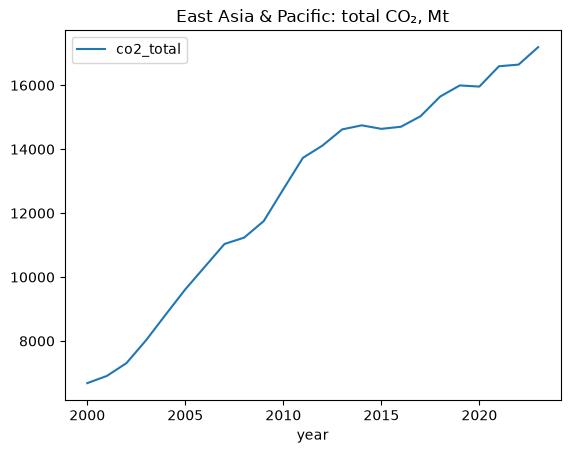

In [173]:
east_asia = regional[regional["region"] == "East Asia & Pacific"]

east_asia.plot(x="year", y="co2_total", title="East Asia & Pacific: total CO₂, Mt")

Worth being clear about how much of this session that one line depends on. The figure is only correct because the aggregates are gone, and they are only gone because the merge used a key that matched, and we only know the key matched because we counted the rows. Every silent failure in this notebook would have produced a chart that looked exactly as convincing as this one.

We come back to how to make figures worth showing somebody.

## Additional resources

- [Group by: split-apply-combine](https://pandas.pydata.org/docs/user_guide/groupby.html) - the
  official account, including the full list of aggregation and transformation methods
- [Merge, join, concatenate and compare](https://pandas.pydata.org/docs/user_guide/merging.html) -
  every way of putting two tables together, with diagrams
- [Time series and date functionality](https://pandas.pydata.org/docs/user_guide/timeseries.html) -
  long, but the tables of `.dt` properties and of `resample` frequency codes are worth bookmarking
- [strftime.org](https://strftime.org/) - a one-page reference for every date format code
- [SKL401](https://isabelhovdahl.github.io/skl401/) - lesson 3.7 covers grouping and aggregation, 3.8
  joining, and 3.9 dates

**Next week:** turning these tables into figures - what makes a chart readable, and how to write one
function that draws the same plot for any country you hand it.